In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay, accuracy_score)


header = ['comment_id', 'text', 'date', 'song', 'artist', 'kendrick_score', 'drake_score']
dataset = pd.read_csv(filepath_or_buffer='./cleaned_comments/cleaned_comments.csv',  delimiter=',', names=header, skiprows=1)
dataset

,comment_id,text,date,song,artist,kendrick_score,drake_score
0,Ugzc5Srhx8p6qzdSjvB4AaABAg,Kendrick responded so fast I didnt know Drake ...,2024-05-04 12:59:37+00:00,Family_Matters,BagOnly_Drake,2,-1
1,UgxGl-mJYHo4mzjNy0R4AaABAg,Beat switches each time a different ghost writ...,2024-05-04 08:41:23+00:00,Family_Matters,BagOnly_Drake,0,-2
2,Ugw8sI-rRjgKXTUCBFV4AaABAg,Kendrick had a diss ready for this song not ev...,2024-05-04 05:18:35+00:00,Family_Matters,BagOnly_Drake,2,0
3,UgzkG6vRyh2O9FOlnJR4AaABAg,Imagine sitting down in a group and writing th...,2024-05-04 17:04:41+00:00,Family_Matters,BagOnly_Drake,1,-1
4,UgyRU5sH2RugrPSNal94AaABAg,ngl Drake's melody is fire\n\nbut Kendrick's l...,2024-05-05 06:28:06+00:00,Family_Matters,BagOnly_Drake,3,2
...,...,...,...,...,...,...,...
5693,Ugy_pfO-XFQhO5gGBA94AaABAg,"''I agree'' with you, this track is so deep th...",2024-05-05 10:59:39+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5694,UgwKaRbSQ7CT8Id9UlJ4AaABAg,"It's like y'all came in expecting a comedy, wa...",2024-05-04 21:19:33+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3
5695,UgwKuRsl6mRT319BxZB4AaABAg,Kendrick gave you all the bars and metaphors y...,2024-05-05 05:00:26+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5696,UgxGzHrFJUiB4cJv-7t4AaABAg,Never thought I would think this channel would...,2024-05-04 22:54:04+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2


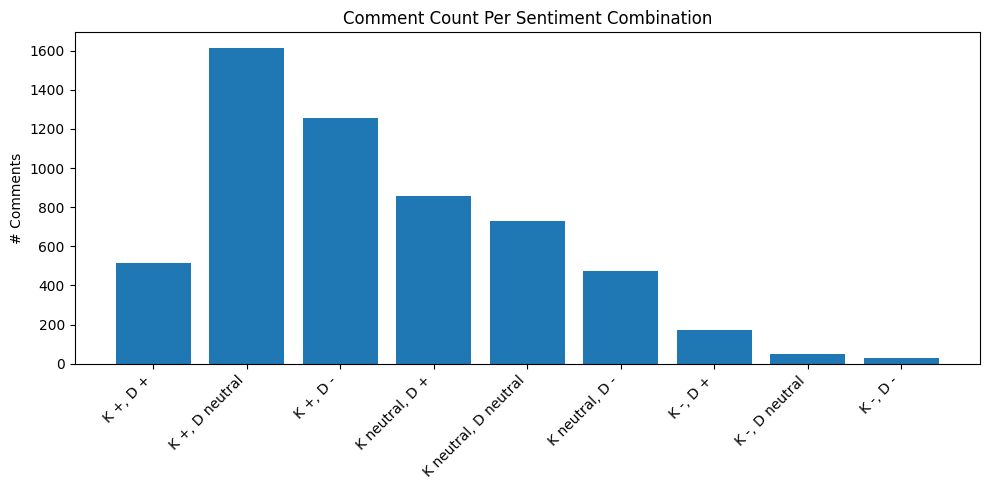

In [2]:
#pulling together the same labeled data as the naive bayes -- I think trying to 
#fit how I originally wanted to (to predict each combination) is again slicing too
#fine. so we'll see how the coarser method works

signs = {1: '+', 0: 'neutral', -1: '-'}

k_signs = np.sign(dataset['kendrick_score']).astype(int).map(signs)
d_signs = np.sign(dataset['drake_score']).astype(int).map(signs)

youtube_comment_texts = dataset['text'].values
youtube_comment_labels = ('K ' + k_signs + ', D ' + d_signs).values

order = ['+', 'neutral', '-']
all_labels = [f"K {k}, D {d}" for k in order for d in order]

counts = pd.Series(youtube_comment_labels).value_counts().reindex(all_labels, fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=45, ha='right')
plt.ylabel('# Comments')
plt.title('Comment Count Per Sentiment Combination')
plt.tight_layout()
plt.show()

In [3]:
dataset['net_score'] = dataset['kendrick_score'] - dataset['drake_score']
# data = dataset[dataset['net_score'] != 0].copy()
# data['favors_kendrick'] = (data['net_score'] > 0).astype(int)
dataset['favors_kendrick'] = (dataset['net_score'] > 0).astype(int)

#splitting on whether it favors kendrick (0, 1)
train_df, test_df = train_test_split(dataset, test_size=0.2, random_state=3643,
                                     stratify=dataset['favors_kendrick'])

# print(len(dataset), '->', len(data))
# print(data['favors_kendrick'].value_counts(normalize=True))   # class balance

# train_df, test_df = train_test_split(data, test_size=0.2, random_state=3643,
#                                      stratify=data['favors_kendrick'])

train_df

,comment_id,text,date,song,artist,kendrick_score,drake_score,net_score,favors_kendrick
2448,UgxP0qWKa7D_MecJPQl4AaABAg,2:06 bro WHAT,2024-05-06 01:58:37+00:00,The_Heart_Part_6,Drake,0,-3,3,1
5453,Ugz0KavTRKT41puTo814AaABAg,Drake calling Kendrick short for the 100th is ...,2024-05-04 21:10:13+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3,6,1
1512,UgyqaNGFcEc2FHVWAgl4AaABAg,nah ima tell my kids this was the Epic Rap Bat...,2024-05-04 14:35:42+00:00,Family_Matters,Drake,0,1,-1,0
443,Ugxn75zlUFq_P7PvIj54AaABAg,THIS SONG IS WHAT I NEEDED!! SNATCHED MY EDGES...,2023-10-08 10:22:31+00:00,First_Person_Shooter,Drake,0,3,-3,0
2150,Ugw-IJ2rxWcR2u35KYp4AaABAg,Kendrick just proved to J. Cole he can drop do...,2024-05-05 05:08:02+00:00,Not_Like_Us,Kendrick_Lamar,2,0,2,1
...,...,...,...,...,...,...,...,...,...
5489,Ugz4A9CecZbxHffINdZ4AaABAg,Damn the bald dude can't hide his hate. He don...,2024-05-05 11:12:46+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2,4,1
4118,UgzHUqf4rWjGFaGcs4R4AaABAg,Kendrick was so hyped about that OVO mole not ...,2024-05-04 19:03:54+00:00,616_in_LA,LostInVegas_Kendrick_Lamar,-3,2,-5,0
2468,UgyxSnsXxGs-O0jcUTB4AaABAg,This entire beef got me back tuned into rap mu...,2024-05-06 02:45:56+00:00,The_Heart_Part_6,Drake,2,2,0,0
230,UgzQLxtolnMSY1W7lkl4AaABAg,Yo Kendrick Lamar diss is way better than drak...,2024-07-08 04:52:10+00:00,Family_Matters,BagOnly_Drake,2,-2,4,1


In [4]:
test_df

,comment_id,text,date,song,artist,kendrick_score,drake_score,net_score,favors_kendrick
2984,UgwL1Lt-cbBXPcDV6PF4AaABAg,I just know Metro Boomin will always drop Bang...,2024-05-13 06:51:25+00:00,Like_That,VibeMusic_Future,0,0,0,0
1255,UgwCxjn8pfzN4VdO9pl4AaABAg,Yet another song for Adonis to play when he ge...,2024-05-03 17:22:46+00:00,616_in_LA,RapNation_Kendrick_Lamar,1,-1,2,1
4730,UgyZtzXD1ADKtPG8wNR4AaABAg,Ben was Michael Jackson's pet rat that Joe Jac...,2024-05-01 07:54:17+00:00,Euphoria,LostInVegas_Kendrick_Lamar,0,0,0,0
2683,UgzSaKX2uSZyLouyQmx4AaABAg,Drake just making noises,2023-11-24 17:31:19+00:00,First_Person_Shooter,RapCity_Drake,0,-1,1,1
2532,Ugztmg2B7119pUIR5ct4AaABAg,"It's J Cole 🐐.. No disrespect to no one else, ...",2023-10-19 01:46:00+00:00,First_Person_Shooter,RapCity_Drake,0,0,0,0
...,...,...,...,...,...,...,...,...,...
1149,UgwBbgZfA7cqXcuS2B54AaABAg,"This is the best joint out of the ENTIRE ""beef""",2024-07-23 15:27:45+00:00,Euphoria,Kendrick_Lamar,2,-2,4,1
4546,UgzMnW-WB0vPGzBYK4N4AaABAg,"As a Canadian, I'm cheesin fam. The man went o...",2024-05-01 19:24:13+00:00,Euphoria,VibesOnly_Kendrick_Lamar,3,-3,6,1
3475,UgyV0j9g5T5ccUIRmEZ4AaABAg,"Drake really went from ""DROP DROP DROP"" to ""ST...",2024-05-30 08:26:01+00:00,Push_Ups,BagOnly_Drake,3,-3,6,1
3860,Ugy0S7eV0fqB-p0Kail4AaABAg,Drizzy cooked here 🔥🔥🔥🔥🔥,2024-04-14 20:34:58+00:00,Push_Ups,KnoxHill_Drake,0,2,-2,0


In [15]:
#limiting to only the most popular features since there's a TON of words across all comments
Tfidf = TfidfVectorizer(max_features=500, min_df=5)
X_train = Tfidf.fit_transform(train_df['text'])
X_test = Tfidf.transform(test_df['text'])

#running linear regression on the data
LRmodel = LinearRegression().fit(X_train, train_df['net_score'])
print(f"y = {LRmodel.intercept_} + {LRmodel.coef_[0]}x")

#predicting
pred = LRmodel.predict(X_test)
rmse = np.sqrt(mean_squared_error(test_df['net_score'], pred))
print(f"RMSE: {rmse}\nMAE: {mean_squared_error(test_df['net_score'], pred)}\nR2 score: {r2_score(test_df['net_score'], pred)}")

#getting the baseline to compare
print("Baseline RMSE", np.sqrt(mean_squared_error(
    test_df['net_score'], np.full(len(test_df), train_df['net_score'].mean()))))


y = 0.034700976472080036 + -0.44460753343915604x
RMSE: 2.097151363919623
MAE: 4.398043843189935
R2 score: 0.14422069454300457
Baseline RMSE 2.2676156863847794


In [6]:
coefs = pd.Series(LRmodel.coef_, index=Tfidf.get_feature_names_out()).sort_values()
print(coefs.head(8)); print(coefs.tail(8))

hop        -4.776554
rights     -4.060377
fan        -4.011063
top        -4.003710
long       -3.302645
fire       -2.985172
half       -2.716702
together   -2.600370
dtype: float64
level          3.403734
nothing        3.426349
lost           3.442770
mr             3.450495
hip            4.298859
allegations    4.329606
felt           4.522533
kendrick       4.861786
dtype: float64


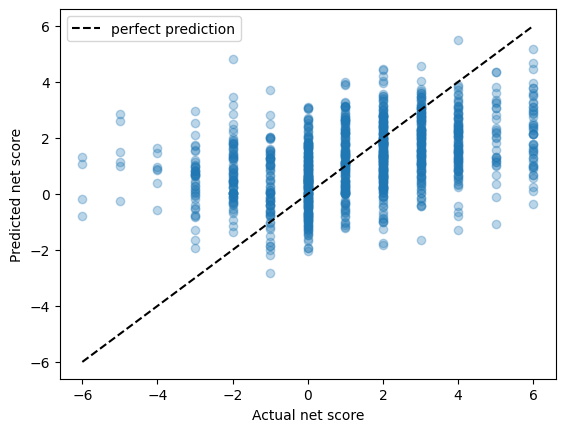

In [7]:
plt.scatter(test_df['net_score'], pred, alpha=0.3)
plt.plot([-6, 6], [-6, 6], 'k--', label='perfect prediction')
plt.xlabel('Actual net score')
plt.ylabel('Predicted net score')
plt.legend()
plt.show()

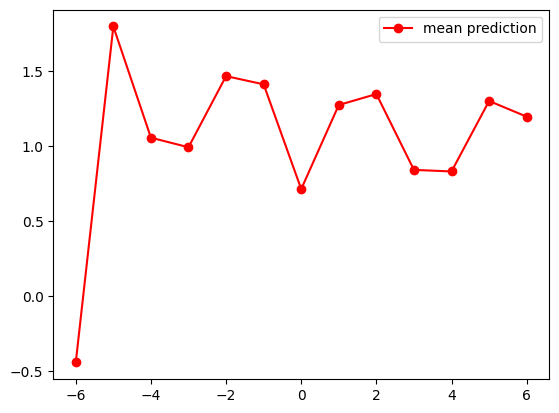

In [8]:
means = pd.Series(pred).groupby(test_df['net_score']).mean()
plt.plot(means.index, means.values, 'r-o', label='mean prediction')
plt.legend()

Logistic Regression model accuracy: 0.7271929824561404
mr            5.142768
an            5.180478
minor         5.385314
kdot          5.808605
lost          5.830689
drakes        6.333263
euphoria      8.410789
kendrick    122.856283
dtype: float64


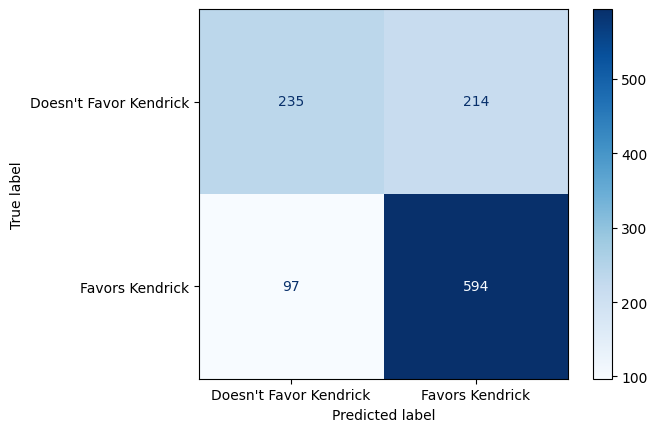

In [9]:
#Logistic regression, now
LogRmodel = LogisticRegression(max_iter=1000).fit(X_train, train_df['favors_kendrick'])

#predicting
y_pred = LogRmodel.predict(X_test)

#generating stats
print(f"Logistic Regression model accuracy: {accuracy_score(test_df['favors_kendrick'], y_pred)}")
#conf matrix
ConfusionMatrixDisplay(confusion_matrix(test_df['favors_kendrick'], y_pred),
                       display_labels=["Doesn't Favor Kendrick", 'Favors Kendrick']).plot(cmap='Blues')
log_coefs = pd.Series(LogRmodel.coef_[0], index=Tfidf.get_feature_names_out())
print(np.exp(log_coefs.sort_values()).tail(8))   # odds multipliers

In [10]:
(dataset['net_score'] == 0).sum()

np.int64(1100)

In [11]:
#comparing this all to naive bayes. since for naive bayes, 
# we used 9 labels and here we've reduced it to just a favors or doesn't, 
# rerunning for an accurate comparison

cv = CountVectorizer()
X_tr = cv.fit_transform(train_df['text'])
X_te = cv.transform(test_df['text'])
nb = MultinomialNB().fit(X_tr, train_df['favors_kendrick'])
print(f"NB accuracy {nb.score(X_te, test_df['favors_kendrick'])}")

NB accuracy 0.7394736842105263


In [13]:
train_df_sample = pd.DataFrame({'text': train_df['text'], 'net_score': train_df['net_score'], 'favors_kendrick': train_df['favors_kendrick'], 'set': 'train'})
test_df_sample = pd.DataFrame({'text': test_df['text'], 'net_score': test_df['net_score'], 'favors_kendrick': test_df['favors_kendrick'], 'set': 'test'})

train_df_sample

,text,net_score,favors_kendrick,set
2448,2:06 bro WHAT,3,1,train
5453,Drake calling Kendrick short for the 100th is ...,6,1,train
1512,nah ima tell my kids this was the Epic Rap Bat...,-1,0,train
443,THIS SONG IS WHAT I NEEDED!! SNATCHED MY EDGES...,-3,0,train
2150,Kendrick just proved to J. Cole he can drop do...,2,1,train
...,...,...,...,...
5489,Damn the bald dude can't hide his hate. He don...,4,1,train
4118,Kendrick was so hyped about that OVO mole not ...,-5,0,train
2468,This entire beef got me back tuned into rap mu...,0,0,train
230,Yo Kendrick Lamar diss is way better than drak...,4,1,train


In [14]:
test_df_sample

,text,net_score,favors_kendrick,set
2984,I just know Metro Boomin will always drop Bang...,0,0,test
1255,Yet another song for Adonis to play when he ge...,2,1,test
4730,Ben was Michael Jackson's pet rat that Joe Jac...,0,0,test
2683,Drake just making noises,1,1,test
2532,"It's J Cole 🐐.. No disrespect to no one else, ...",0,0,test
...,...,...,...,...
1149,"This is the best joint out of the ENTIRE ""beef""",4,1,test
4546,"As a Canadian, I'm cheesin fam. The man went o...",6,1,test
3475,"Drake really went from ""DROP DROP DROP"" to ""ST...",6,1,test
3860,Drizzy cooked here 🔥🔥🔥🔥🔥,-2,0,test
